# Экзаменационная задача №04. Оптимизация рекламной нагрузки для видеоплатформы

**Дисциплина:** Экономика информатизации, лекция №5
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №04: ОПТИМИЗАЦИЯ РЕКЛАМНОЙ НАГРУЗКИ ДЛЯ ПЛАТФОРМЫ ВИДЕОКОНТЕНТА
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №5)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Платформа «ВидеоСервис» зарабатывает и на подписке, и на рекламе. Каждый лишний показ рекламы приносит деньги по CPM,
но раздражает пользователя: больше людей уходит, меньше времени смотрят видео. Получается обычный выбор экономики внимания:
деньги от рекламы сейчас или ценность пользователя в будущем.

**Цель:** найти, сколько показов в день даёт максимальную прибыль, и предложить нагрузку для разных групп пользователей.

**Что нужно сделать:** доход от рекламы, доход от подписки и потери от оттока при разной нагрузке; прибыль и оптимум;
график; чувствительность к CPM и оттоку; рекомендации по сегментам и план мониторинга.

Тема лекции №5: внимание как дефицитный ресурс, модели заработка (CPM), полезность для пользователя с учётом рекламы,
выбор рекламной нагрузки.

## 2. Исходные данные

In [2]:
# 1.1. Параметры платформы (из условия)
users = 5_000_000          # активные пользователи
sub_price = 300            # доход подписки, руб./польз./мес. (ARPU подписки)
CPM = 20                   # руб. за 1000 показов
videos_per_day = 10        # видео в день на пользователя
CAC = 2_000                # руб./пользователь
lifetime = 24              # срок жизни пользователя, мес.
r_year = 0.12; r_m = r_year / 12

# 1.2. Влияние рекламной нагрузки (из условия)
load = pd.DataFrame({"Показов в день": [0, 10, 20, 30, 40, 50, 60],
                     "Отток": [0, 0, 0.02, 0.05, 0.10, 0.18, 0.30],
                     "Время просмотра, мин": [120, 115, 110, 100, 90, 75, 60]})
load

,Показов в день,Отток,"Время просмотра, мин"
0,0,0.00,120
1,10,0.00,115
2,20,0.02,110
3,30,0.05,100
4,40,0.10,90
5,50,0.18,75
6,60,0.30,60


**Допущения:**
- Считаем один месяц после того, как поменяли нагрузку (так заданы формулы в условии), в месяце 30 дней.
- Рекламу видят только те, кто **остался**: $U_{ост}=U(1-отток)$. Ушедшие показов не дают.
- Потеря от ушедшего пользователя разовая: стоимость привлечь нового (CAC) плюс подписка, которую он не заплатит
  за 24 месяца. Отдельно посчитан вариант с дисконтированием этого дохода (1 % в месяц).

## 3. Математическая модель

$$R_{рекл}(x) = U_{ост}(x)\cdot x\cdot 30\cdot\frac{CPM}{1000},\qquad R_{подп}(x)=U_{ост}(x)\cdot 300$$
$$L_{отток}(x)=\Delta U(x)\cdot CAC + \Delta U(x)\cdot ARPU\cdot 24,\qquad \Delta U(x)=U\cdot отток(x)$$
$$\Pi(x)=R_{рекл}(x)+R_{подп}(x)-L_{отток}(x)\ \to\ \max_x$$

Между точками из таблицы отток и время просмотра считаем линейно, с шагом в 1 показ.
Условие оптимума: $\partial R_{рекл}/\partial x = \partial L_{отток}/\partial x + \partial R_{подп}^{потери}/\partial x$.
Проще говоря, последний показ должен приносить столько же, сколько стоит внимание, которое он забирает.

## 4. Реализация расчёта
### 4.1. Доходы, потери и прибыль при разной нагрузке

In [3]:
def profit_table(cpm=CPM, churn_mult=1.0, discount_ltv=False, df=load):
    t = df.copy()
    t["Отток"] = (t["Отток"] * churn_mult).clip(upper=1)
    t["Ушло, млн"] = users * t["Отток"] / 1e6
    t["Осталось, млн"] = users / 1e6 - t["Ушло, млн"]
    t["Показов/мес., млрд"] = t["Осталось, млн"] * 1e6 * t["Показов в день"] * 30 / 1e9
    t["Доход рекламы, млн"] = t["Показов/мес., млрд"] * 1e9 * cpm / 1000 / 1e6
    t["Доход подписки, млн"] = t["Осталось, млн"] * sub_price
    ltv_months = annuity_factor(r_m, lifetime) if discount_ltv else lifetime
    t["Потери оттока, млн"] = t["Ушло, млн"] * (CAC + sub_price * ltv_months)
    t["Прибыль, млн"] = t["Доход рекламы, млн"] + t["Доход подписки, млн"] - t["Потери оттока, млн"]
    return t

base = profit_table()
opt = base.loc[base["Прибыль, млн"].idxmax()]
print(f"Оптимальная нагрузка (по узлам таблицы): {int(opt['Показов в день'])} показов/день; прибыль {opt['Прибыль, млн']:,.1f} млн руб.".replace(",", " "))
base.drop(columns=["Время просмотра, мин"]).set_index("Показов в день").round(2)

Оптимальная нагрузка (по узлам таблицы): 10 показов/день; прибыль 1 530.0 млн руб.


,Отток,"Ушло, млн","Осталось, млн","Показов/мес., млрд","Доход рекламы, млн","Доход подписки, млн","Потери оттока, млн","Прибыль, млн"
Показов в день,,,,,,,,
0,0.00,0.00,5.00,0.00,0.00,1 500.00,0.00,1 500.00
10,0.00,0.00,5.00,1.50,30.00,1 500.00,0.00,1 530.00
20,0.02,0.10,4.90,2.94,58.80,1 470.00,920.00,608.80
30,0.05,0.25,4.75,4.28,85.50,1 425.00,2 300.00,-789.50
40,0.10,0.50,4.50,5.40,108.00,1 350.00,4 600.00,-3 142.00
50,0.18,0.90,4.10,6.15,123.00,1 230.00,8 280.00,-6 927.00
60,0.30,1.50,3.50,6.30,126.00,1 050.00,13 800.00,-12 624.00


In [4]:
# 4.2. Уточнение оптимума на сетке с шагом 1 показ (линейная интерполяция оттока)
grid = pd.DataFrame({"Показов в день": np.arange(0, 61)})
grid["Отток"] = np.interp(grid["Показов в день"], load["Показов в день"], load["Отток"])
grid["Время просмотра, мин"] = np.interp(grid["Показов в день"], load["Показов в день"], load["Время просмотра, мин"])
fine = profit_table(df=grid)
x_opt = int(fine.loc[fine["Прибыль, млн"].idxmax(), "Показов в день"])
print(f"Оптимум на сетке: {x_opt} показов/день; прибыль {fine['Прибыль, млн'].max():,.1f} млн руб.".replace(",", " "))
print(f"Прирост к варианту без рекламы: {fine['Прибыль, млн'].max() - fine.loc[0, 'Прибыль, млн']:.1f} млн руб./мес.")
# Вариант с дисконтированным LTV
disc = profit_table(discount_ltv=True)
print(f"С дисконтированием LTV оптимум: {int(disc.loc[disc['Прибыль, млн'].idxmax(), 'Показов в день'])} показов/день")
# Экономика одного показа против цены внимания
ad_per_show = CPM / 1000
print(f"Доход от 1 показа = {ad_per_show:.3f} руб.; ушедший пользователь стоит {CAC + sub_price*lifetime:,} руб. = "
      f"{(CAC + sub_price*lifetime)/ad_per_show/1e6:.2f} млн показов".replace(",", " "))

Оптимум на сетке: 10 показов/день; прибыль 1 530.0 млн руб.
Прирост к варианту без рекламы: 30.0 млн руб./мес.
С дисконтированием LTV оптимум: 10 показов/день
Доход от 1 показа = 0.020 руб.; ушедший пользователь стоит 9 200 руб. = 0.46 млн показов


### 4.3. Анализ чувствительности

In [5]:
# CPM 10 / 20 / 30 руб.
cpm_rows = []
for c in [10, 20, 30, 60, 120]:
    f = profit_table(cpm=c, df=grid)
    i = f["Прибыль, млн"].idxmax()
    cpm_rows.append({"CPM, руб.": c, "Оптимальная нагрузка": int(f.loc[i, "Показов в день"]),
                     "Макс. прибыль, млн": f.loc[i, "Прибыль, млн"],
                     "Прибыль при 20 показах, млн": f.loc[20, "Прибыль, млн"]})
cpm_sens = pd.DataFrame(cpm_rows)
print("CPM 60 и 120 руб. добавлены для проверки: сдвигается ли оптимум при росте CPM")
cpm_sens

CPM 60 и 120 руб. добавлены для проверки: сдвигается ли оптимум при росте CPM


,"CPM, руб.",Оптимальная нагрузка,"Макс. прибыль, млн","Прибыль при 20 показах, млн"
0,10,10,1 515.00,579.40
1,20,10,1 530.00,608.80
2,30,10,1 545.00,638.20
3,60,10,1 590.00,726.40
4,120,10,1 680.00,902.80


In [6]:
# Отток ±20% при каждом уровне нагрузки
churn_sens = pd.DataFrame({"Показов в день": load["Показов в день"]})
for mlt, lbl in [(0.8, "Отток −20%"), (1.0, "База"), (1.2, "Отток +20%")]:
    churn_sens[lbl] = profit_table(churn_mult=mlt)["Прибыль, млн"].values
churn_sens["Отклонение ±, млн"] = (churn_sens["Отток −20%"] - churn_sens["База"])
churn_sens["Отклонение, % от базы"] = churn_sens["Отклонение ±, млн"] / churn_sens["База"].abs() * 100
churn_sens.set_index("Показов в день").round(1)

,Отток −20%,База,Отток +20%,"Отклонение ±, млн","Отклонение, % от базы"
Показов в день,,,,,
0,1 500.00,1 500.00,1 500.00,0.00,0.00
10,1 530.00,1 530.00,1 530.00,0.00,0.00
20,799.00,608.80,418.60,190.20,31.20
30,-313.60,-789.50,-1 265.40,475.90,60.30
40,-2 189.60,-3 142.00,-4 094.40,952.40,30.30
50,-5 211.60,-6 927.00,-8 642.40,1 715.40,24.80
60,-9 763.20,-12 624.00,-15 484.80,2 860.80,22.70


## 5. Визуализация результатов

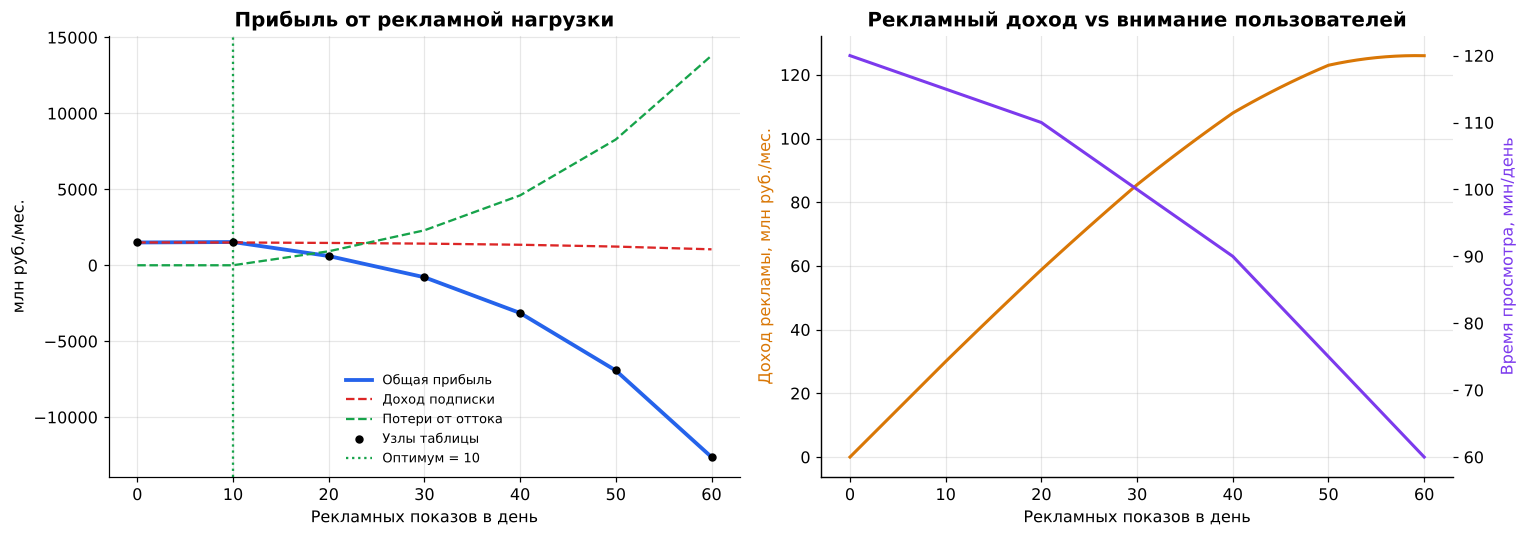

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
ax.plot(fine["Показов в день"], fine["Прибыль, млн"], lw=2.5, label="Общая прибыль")
ax.plot(fine["Показов в день"], fine["Доход подписки, млн"], lw=1.5, ls="--", label="Доход подписки")
ax.plot(fine["Показов в день"], fine["Потери оттока, млн"], lw=1.5, ls="--", label="Потери от оттока")
ax.scatter(base["Показов в день"], base["Прибыль, млн"], color="black", zorder=3, s=20, label="Узлы таблицы")
ax.axvline(x_opt, color=PALETTE[2], ls=":", label=f"Оптимум = {x_opt}")
ax.set_xlabel("Рекламных показов в день"); ax.set_ylabel("млн руб./мес."); ax.set_title("Прибыль от рекламной нагрузки")
ax.legend(fontsize=8.5)
ax = axes[1]
ax.plot(fine["Показов в день"], fine["Доход рекламы, млн"], lw=2, color=PALETTE[3])
ax.set_ylabel("Доход рекламы, млн руб./мес.", color=PALETTE[3])
ax2 = ax.twinx(); ax2.plot(grid["Показов в день"], grid["Время просмотра, мин"], lw=2, color=PALETTE[4])
ax2.set_ylabel("Время просмотра, мин/день", color=PALETTE[4]); ax2.grid(False)
ax.set_xlabel("Рекламных показов в день"); ax.set_title("Рекламный доход vs внимание пользователей")
plt.tight_layout(); plt.show()

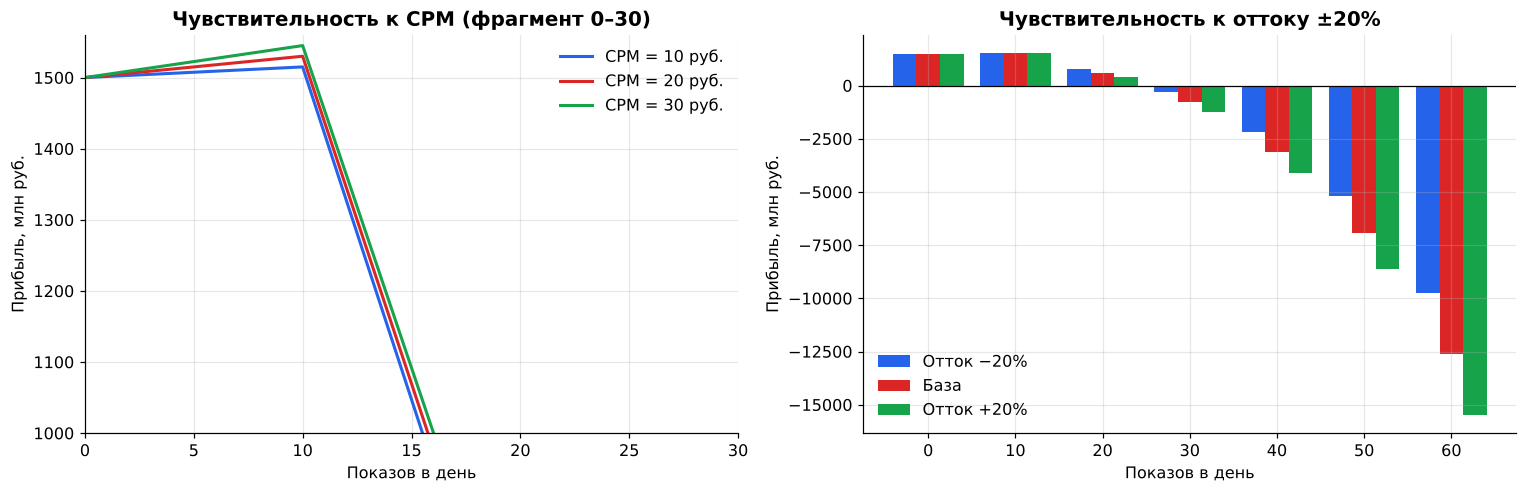

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
ax = axes[0]
for c in [10, 20, 30]:
    f = profit_table(cpm=c, df=grid); ax.plot(f["Показов в день"], f["Прибыль, млн"], lw=2, label=f"CPM = {c} руб.")
ax.set_xlim(0, 30); ax.set_ylim(1000, 1560)
ax.set_xlabel("Показов в день"); ax.set_ylabel("Прибыль, млн руб."); ax.set_title("Чувствительность к CPM (фрагмент 0–30)")
ax.legend()
ax = axes[1]
x = np.arange(len(churn_sens)); w = 0.27
for i, col in enumerate(["Отток −20%", "База", "Отток +20%"]):
    ax.bar(x + (i - 1) * w, churn_sens[col], w, label=col)
ax.set_xticks(x, churn_sens["Показов в день"]); ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Показов в день"); ax.set_ylabel("Прибыль, млн руб."); ax.set_title("Чувствительность к оттоку ±20%")
ax.legend()
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Реклама приносит мало по сравнению с подпиской.** При 10 показах в день реклама даёт около 30 млн руб. в месяц, подписка
  1 500 млн руб. Один показ стоит 0,02 руб., а один ушедший пользователь 9 200 руб. (CAC + 24 месяца подписки).
  Это как **460 тыс. показов**. Поэтому даже небольшой рост оттока сразу съедает весь доход от рекламы.
- **Оптимум 10 показов в день** (прибыль около 1 530 млн руб.). До этого уровня никто не уходит, и реклама даёт деньги «бесплатно».
  Уже при 20 показах уходят 2 % пользователей (100 тыс. человек). Это около 920 млн руб. потерь, прибыль падает примерно на 60 %.
  После 30–40 показов прибыль уходит в минус. Более мелкая сетка и дисконтирование оптимум не меняют.
- **CPM.** При обычных 10–30 руб. оптимум остаётся на 10 показах: выше CPM, выше прибыль, но баланс тот же.
  Даже при CPM 120 руб. (в 6 раз выше) оптимум не сдвигается. Он поменяется, только когда показы будут приносить
  столько же, сколько стоит ушедший пользователь.
- **Отток.** На большой нагрузке прибыль сильно зависит от оттока: ±20 % оттока меняют прибыль на сотни миллионов.
  При нагрузке до 10 показов риска нет, там отток нулевой.
- **Экономика внимания.** Время просмотра падает со 120 до 60 минут. Пользователи «платят» вниманием, и если продавать
  рекламодателям слишком много внимания, платформа теряет свой главный актив.

## 7. Выводы и рекомендации

**Главный вывод:** лучше всего **10 показов в день**. Поднимать нагрузку невыгодно при любом реальном CPM.

**Нагрузка по группам пользователей**
| Группа | Нагрузка | Почему |
|---|---|---|
| Платные подписчики | 0–3 показа в день или без рекламы | они платят подпиской, реклама может отпугнуть самых ценных |
| Бесплатные пользователи | 10–15 показов в день | подписки нет, терять меньше, реклама основной доход с них |
| Новые (первый месяц) | 3–5 показов в день | легко уходят, привычка ещё не сложилась |
| Неактивные | 0 | показы почти ничего не стоят, а реклама ускоряет уход |
| Очень активные | до 15 показов, короткие форматы | терпят рекламу лучше, CPM выше |

Ещё можно ввести «тариф без рекламы» дороже обычного: так платформа зарабатывает на тех, кто не хочет смотреть рекламу.

**План мониторинга**
| Метрика | Как часто | Порог | Что делать |
|---|---|---|---|
| Отток по группам нагрузки | ежедневно или еженедельно | рост больше 0,5 п.п. | снизить нагрузку в группе на 20 % |
| Время просмотра на пользователя | ежедневно | падение больше 5 % | проверить частоту и формат показов |
| Доход на пользователя (подписка + реклама) | еженедельно | снижение | пересмотреть баланс подписки и рекламы |
| CPM и заполняемость | ежедневно | CPM ниже 15 руб. | меньше показов, точнее таргетинг |
| NPS и жалобы на рекламу | ежемесячно | NPS ниже 40 | A/B-тест с меньшей нагрузкой |
| A/B-тесты нагрузки | постоянно | нет | уточнять, как нагрузка влияет на отток |